# Uber's three objections, answered by defending under challenge and the appendix: which objection holds?

**Week 4, Tuesday, chapter 5, the case's second chapter.** It applies defending under
challenge: restate, answer, concede, what would change your mind (concept notebook 03), and
what to leave out, and the appendix (concept notebook 02). At Gulmohar Secondary School
(invented), notebook 03 conceded the exams' 8 points and answered with the 4.7 points weeks
3 to 5 gained before any exam. Notebook 04 left the city head's slide on one number: gross
bookings per peak online hour fell from Rs 314 to Rs 260 because trips per online hour fell
from 1.90 to 1.58, with the fare flat at Rs 165. This notebook finds the true part of each
role's objection in the case's own tables and answers the rest.

**The ticket.** Uber, Hyderabad, the driver app's peak-hour earnings guarantee: an enrolled
driver online through a peak window is guaranteed Rs 300 per peak online hour, and Uber
pays the gap as a top-up. Monday's redesign pays per completed peak trip, with a floor kept
for drivers who accept at least half their offers. Three roles object at Thursday's review. Driver
operations: "Drivers will log off and supply at peak will fall." Marketing: "The guarantee is
on every hoarding; changing it six weeks in looks like bait." Finance: "The fall in bookings
per hour is the monsoon ending."

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**Who needs the answer.** The analyst whose slide must survive three roles who each lose
something under it, and the city head, who sides with nobody until the evidence is on the
table. A defence that overclaims turns a partly right objector against the test; one that
retreats keeps paying for idle hours.

**The metric at stake.** Trips per peak online hour, 1.90 before the launch and 1.58 after,
the line the slide's evidence stands on.

**The questions on the way.**

1. Which drivers' trips per hour fell?
2. Are the 140 drivers who joined after the hoarding in the idle tail?
3. Did demand fall away with the monsoon?
4. What does a full defence of the monsoon objection sound like?
5. What goes behind the slide, page by page?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

segments = pd.read_csv("../data/C2_W04_D02_driver_segments_STUDENT.csv")   # Monday's drivers in three groups
weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")         # the city, week by week
print(segments.to_string(index=False))
city = weeks.groupby("window")[["peak_online_hours", "peak_trips"]].sum()
seg = segments.groupby("window")[["peak_online_hours", "peak_trips"]].sum()
check("the three groups add up to the city's hours and trips in both windows", seg.equals(city.loc[seg.index]))
check("1,060 drivers before the launch and 1,200 after",
      segments.groupby("window").drivers.sum().to_dict() == {"after": 1200, "before": 1060})

                                  segment window  drivers  peak_online_hours  peak_trips
                            the idle tail before      180              20000       38000
                            the idle tail  after      180              42000       33440
the other drivers there before the launch before      880              98000      186200
the other drivers there before the launch  after      880             102000      193800
                          the 140 joiners  after      140               2300        3660
PASS the three groups add up to the city's hours and trips in both windows
PASS 1,060 drivers before the launch and 1,200 after


## Which drivers' trips per hour fell?

Driver operations' objection first. The **idle tail** is Monday's name for the 180 drivers
whose trips per online hour fell under 1.0 after the launch; the other 880 drivers were
there before the launch too; the 140 joiners arrived after it.

**Predict before you run.** Which group's trips per online hour fell?

a) All three
b) The idle tail only
c) The 140 joiners only
d) The other 880 drivers

window                                     before  after
segment                                                 
the 140 joiners                               NaN   1.59
the idle tail                                 1.9   0.80
the other drivers there before the launch     1.9   1.90
the idle tail's share of peak online hours after the launch: 29%
PASS the idle tail fell from 1.90 to under 1.0
PASS the other 880 held at 1.90


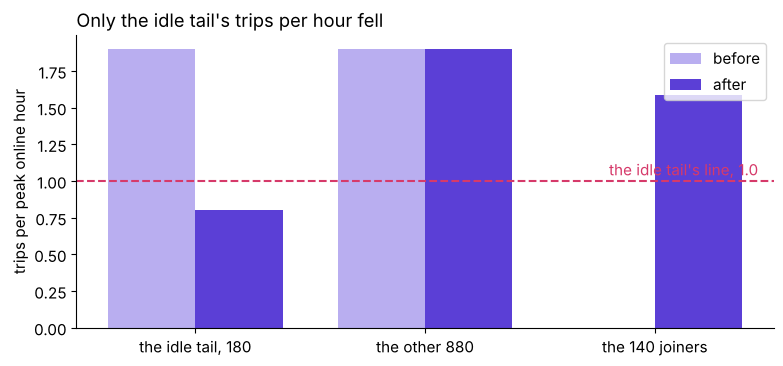

In [2]:
segments["trips_per_hour"] = (segments.peak_trips / segments.peak_online_hours).round(2)
tph = segments.pivot(index="segment", columns="window", values="trips_per_hour")[["before", "after"]]
print(tph.to_string())
tail_hours = segments[(segments.segment == "the idle tail") & (segments.window == "after")].peak_online_hours.iloc[0]
tail_share = tail_hours / city.loc["after", "peak_online_hours"]
print(f"the idle tail's share of peak online hours after the launch: {tail_share:.0%}")
check("the idle tail fell from 1.90 to under 1.0", tph.loc["the idle tail"].tolist() == [1.90, 0.80])
check("the other 880 held at 1.90", tph.loc["the other drivers there before the launch"].tolist() == [1.90, 1.90])

fig, ax = plt.subplots(figsize=(9, 3.8))
order = ["the idle tail", "the other drivers there before the launch", "the 140 joiners"]
short = ["the idle tail, 180", "the other 880", "the 140 joiners"]
for k, window in enumerate(["before", "after"]):
    vals = [tph.loc[s, window] for s in order]
    ax.bar([i + (k - 0.5) * 0.38 for i in range(3)], vals, width=0.38,
           color=LILAC if window == "before" else VIOLET, label=window)
ax.axhline(1.0, color=ROSE, ls="--")
ax.text(2.45, 1.04, "the idle tail's line, 1.0", color=ROSE, ha="right")
ax.set_xticks(range(3), short)
ax.set_ylabel("trips per peak online hour")
ax.set_title("Only the idle tail's trips per hour fell", loc="left")
ax.legend()
plt.show()

**What happened.** The answer is b. The idle tail fell from 1.90 trips per online hour to
0.80 on 42,000 hours, 29 percent of all peak online hours after the launch, while the other
880 held at 1.90 and the joiners ran at 1.59. Driver operations' true part: the 180 will
log off, since their idle hours are exactly what stops being paid. The rest is answered by
the 880, who kept their trips per hour and keep the floor if they accept.

## Are the 140 drivers who joined after the hoarding in the idle tail?

Marketing's objection: the hoarding promised a floor, and 140 drivers joined after it went
up. If the joiners were the idle tail, the redesign would punish exactly the drivers the
hoarding recruited.

**Predict before you run.** How many of the 140 joiners sit in the idle tail?

a) All 140
b) About half
c) None
d) The tables cannot say

In [3]:
joiners = segments[segments.segment == "the 140 joiners"].iloc[0]
tail = segments[(segments.segment == "the idle tail") & (segments.window == "before")].iloc[0]
print(f"the joiners ran {joiners.trips_per_hour} trips per online hour, against the idle tail's line of 1.0")
print(f"the idle tail is {tail.drivers} drivers who were there before the launch")
check("the joiners sit above the idle tail's line", joiners.trips_per_hour > 1.0)
check("the idle tail was drawn from the drivers there before the launch",
      tail.drivers + 880 == segments[segments.window == "before"].drivers.sum())

the joiners ran 1.59 trips per online hour, against the idle tail's line of 1.0
the idle tail is 180 drivers who were there before the launch
PASS the joiners sit above the idle tail's line
PASS the idle tail was drawn from the drivers there before the launch


**What happened.** The answer is c. The idle tail is 180 of the 1,060 drivers who were
there before the launch, so no joiner is in it, and the joiners ran 1.59 trips per online
hour, well above the tail's line of 1.0. Marketing's true part stands: the hoarding
promised a floor, and changing it needs words drivers will accept. The rest is answered:
the floor stays for drivers who accept, and the joiners are not the drivers it stops
paying.

## Did demand fall away with the monsoon?

Finance's objection is the hardest, because part of it cannot be answered from these
tables: the monsoon ended inside the six weeks, and last year's weeks are not in the data.

**Predict before you run.** Over the six weeks after the launch, rider requests rose 1.8
percent on the six before. Does that settle finance's objection?

a) Yes: demand held, so the monsoon explains nothing
b) No: read the weeks one by one before using a six-week total
c) Yes: trips rose 3 percent as well
d) No: requests can never check anything about trips

six weeks on six weeks: requests +1.8%
the last three weeks: requests 41,161 to 42,602, against 41,155 to 42,719 before the launch
the last three weeks: 1.56 trips per online hour, against 1.90 before
PASS requests fell four weeks running from 7 September
PASS the last three weeks' requests sit inside the before window's range
PASS trips per online hour stayed low in the last three weeks


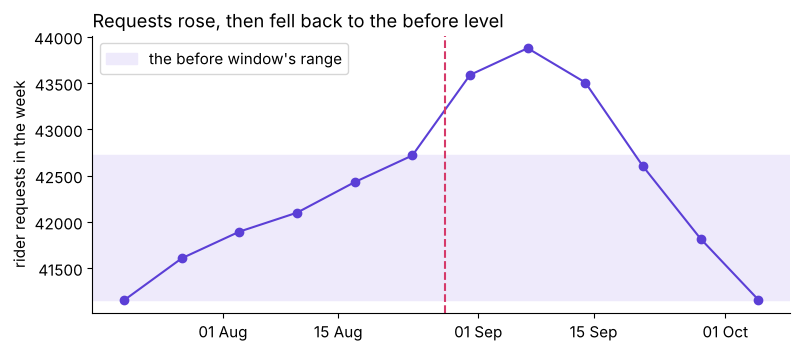

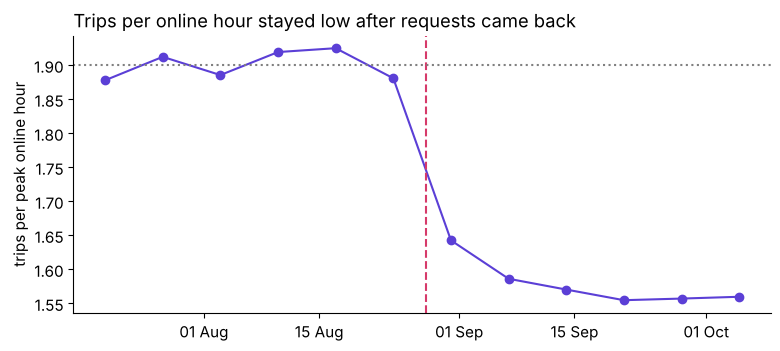

In [4]:
import matplotlib.dates as mdates
w = weeks.set_index(pd.to_datetime(weeks.week_start))
before, after = w[w.window == "before"], w[w.window == "after"]
rise = after.rider_requests.sum() / before.rider_requests.sum() - 1
falls = (after.rider_requests.diff() < 0).iloc[2:].sum()             # week on week, from 7 September on
last3 = after.iloc[-3:]
last3_tph = last3.peak_trips.sum() / last3.peak_online_hours.sum()
print(f"six weeks on six weeks: requests {rise:+.1%}")
print(f"the last three weeks: requests {last3.rider_requests.min():,} to {last3.rider_requests.max():,}, "
      f"against {before.rider_requests.min():,} to {before.rider_requests.max():,} before the launch")
print(f"the last three weeks: {last3_tph:.2f} trips per online hour, against 1.90 before")
check("requests fell four weeks running from 7 September", falls == 4)
check("the last three weeks' requests sit inside the before window's range",
      last3.rider_requests.between(before.rider_requests.min(), before.rider_requests.max()).all())
check("trips per online hour stayed low in the last three weeks", round(last3_tph, 2) == 1.56)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhspan(before.rider_requests.min(), before.rider_requests.max(), color=PALE, label="the before window's range")
ax.plot(w.index, w.rider_requests, color=VIOLET, marker="o")
ax.axvline(pd.Timestamp("2026-08-28"), color=ROSE, ls="--")
ax.set_ylabel("rider requests in the week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Requests rose, then fell back to the before level", loc="left")
ax.legend(loc="upper left")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(w.index, w.peak_trips / w.peak_online_hours, color=VIOLET, marker="o")
ax.axvline(pd.Timestamp("2026-08-28"), color=ROSE, ls="--")
ax.axhline(1.90, color="gray", ls=":")
ax.set_ylabel("trips per peak online hour")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("Trips per online hour stayed low after requests came back", loc="left")
plt.show()

**What happened.** The answer is b. Requests rose in the launch weeks and then fell four
weeks running from 7 September, so the six-week rise of 1.8 percent hides a decline. In
the last three weeks requests were back inside the before window's range, 41,161 to 42,602
against 41,155 to 42,719, and trips per online hour still ran at 1.56: with demand at its
old level, each online hour carried fewer trips than before.

**The plausible wrong answer.** "Requests rose 1.8 percent over the six weeks, so demand
held and the monsoon explains nothing." **Why it is wrong.** It concedes nothing, and the
finance partner, who can see the weekly decline, turns the room against the test. **The
check:** read the weeks one by one before quoting a total. **The fix:** concede the decline
and the missing year, and answer with the last three weeks.

## What does a full defence of the monsoon objection sound like?

Notebook 03's four moves, restated here so this notebook stands alone: restate, answer,
concede, what would change your mind. The answer names a line of evidence the cells
computed.

In [5]:
def defend(restate, answer, concede, change_mind):
    """Defending under challenge: restate, answer, concede, what would change your mind."""
    moves = {"restate": restate, "answer": answer, "concede": concede, "change my mind": change_mind}
    for move, words in moves.items():
        print(f"{move:>15}: {textwrap.fill(words, 110, subsequent_indent=' ' * 17)}")
    return moves

moves = defend(
    restate="You are saying the fall in bookings per hour could be the season ending, so the scheme has not had a fair test.",
    answer=(f"In the last three weeks requests were back at the before window's level and trips per online hour still "
            f"ran at {last3_tph:.2f}; the 880 drivers there before the launch held at 1.90, so the fall sits in the idle tail."),
    concede="You are right that the monsoon ended inside the six weeks, and that last year's weeks are not in the data.",
    change_mind=("Last year's same six weeks showing a fall of this size, or the test of the redesign showing no change "
                 "in trips per online hour."))
check("the answer names a line of evidence", "1.56" in moves["answer"])
check("the concession says the true part", "monsoon" in moves["concede"])

        restate: You are saying the fall in bookings per hour could be the season ending, so the scheme has not had a fair
                 test.
         answer: In the last three weeks requests were back at the before window's level and trips per online hour still ran at
                 1.56; the 880 drivers there before the launch held at 1.90, so the fall sits in the idle
                 tail.
        concede: You are right that the monsoon ended inside the six weeks, and that last year's weeks are not in the data.
 change my mind: Last year's same six weeks showing a fall of this size, or the test of the redesign showing no change in trips
                 per online hour.
PASS the answer names a line of evidence
PASS the concession says the true part


## What goes behind the slide, page by page?

Notebook 02's sort, applied: the slide keeps its claim, its evidence, its caveat and its
action, and each role's question gets one appendix page headed by that question. The
monsoon stays on the slide as the caveat; a caveat found in the drawer makes its owner call
the slide dishonest.

In [6]:
slide_caveat = "The monsoon ended inside the six weeks, so part of the fall may be the season."
drawer = {
    "Driver operations asks: what happens to the drivers who accept?":
        f"The 880 there before the launch ran {tph.loc['the other drivers there before the launch', 'after']:.2f} trips per online hour after it.",
    "Marketing asks: do the 140 new drivers lose out?":
        f"No joiner is in the idle tail; the joiners ran {joiners.trips_per_hour} trips per online hour.",
    "Finance asks: how much of the fall is the season?":
        f"In the last three weeks requests were back at the before level and trips per hour ran at {last3_tph:.2f}.",
}
print("On the slide, the caveat:", slide_caveat)
for heading, line in drawer.items():
    print(f"Appendix page. {heading}\n    {line}")
check("the caveat sits on the slide, never only in the drawer", "monsoon" in slide_caveat)
check("one page per role, each headed by its question", len(drawer) == 3 and all("?" in h for h in drawer))

On the slide, the caveat: The monsoon ended inside the six weeks, so part of the fall may be the season.
Appendix page. Driver operations asks: what happens to the drivers who accept?
    The 880 there before the launch ran 1.90 trips per online hour after it.
Appendix page. Marketing asks: do the 140 new drivers lose out?
    No joiner is in the idle tail; the joiners ran 1.59 trips per online hour.
Appendix page. Finance asks: how much of the fall is the season?
    In the last three weeks requests were back at the before level and trips per hour ran at 1.56.
PASS the caveat sits on the slide, never only in the drawer
PASS one page per role, each headed by its question


## Does a second route reach the 880's 1.90?

The segments table gives the 880's trips per hour directly. The city's totals less the idle
tail and the joiners give it a second way, which is what a finance partner would do with
Monday's dashboard alone.

In [7]:
after_city = city.loc["after"]
rest = segments[(segments.window == "after") & (segments.segment != "the other drivers there before the launch")]
hours_880 = after_city.peak_online_hours - rest.peak_online_hours.sum()
trips_880 = after_city.peak_trips - rest.peak_trips.sum()
print(f"city less the tail and the joiners: {trips_880:,} trips over {hours_880:,} hours, {trips_880 / hours_880:.2f} an hour")
check("the second route agrees with the segments table", round(trips_880 / hours_880, 2) == 1.90)

city less the tail and the joiners: 193,800 trips over 102,000 hours, 1.90 an hour
PASS the second route agrees with the segments table


**The answers, one line each.**

1. Only the idle tail's trips per hour fell, 1.90 to 0.80; the other 880 held at 1.90.
2. None of the 140 joiners is in the idle tail; they ran 1.59 trips per online hour.
3. Requests fell four weeks running from 7 September, then sat at the before level while
   trips per online hour stayed at 1.56; the missing year is conceded.
4. Restate, answer from the last three weeks and the 880, concede the monsoon and the
   missing year, and name last year's weeks as the fact that would change your mind.
5. Three appendix pages, each headed by a role's question; the monsoon stays on the slide.

### What will an interviewer ask about this, and what does a strong answer do?

**[F] A stakeholder's objection is partly right; how do you answer it?** Say its true part
first, out loud, then answer the rest from one named line of evidence, and end on the fact
that would change your mind, so the room hears a claim that can be tested.

**[D] What do you do when the person who loses under your claim runs the meeting?** Concede
the true part before the meeting, keep their visible number on the page, and agree the test
and the result that decides it in advance.

**The AI-company variant.** A head of product objects to replacing acceptance rate in the
sales deck: "acceptance is what customers see." The true part: customers do quote it, and
it moves first. The answer, on invented numbers: of every 100 suggestions shown, 32 are
accepted, and if a fifth of those are deleted within a week, about 26 survive. The defence
keeps acceptance as a leading input and judges the team on surviving code per paid seat,
with the fact that would change the call: last year's renewals showing that acceptance
separates the accounts that renewed from those that cut seats as well as surviving code
does.